<a href="https://colab.research.google.com/github/iliadis97/ml-assignments/blob/main/assignment_1/ml_supervised_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ΕΡΓΑΣΙΑ 1 - ΕΠΙΒΛΕΠΟΜΕΝΗ ΜΑΘΗΣΗ

### ΕΙΣΑΓΩΓΗ ΒΙΒΛΙΟΘΗΚΩΝ

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler

## ΜΕΡΟΣ 1 - ΛΟΓΙΣΤΙΚΗ ΠΑΛΙΝΔΡΟΜΗΣΗ

### ΕΡΩΤΗΜΑ 1

Για να λειτουργήσει σωστά η φόρτωση των δεδομένων, υποθέτουμε ότι το αρχείο diabetes.csv βρίσκεται στον ίδιο φάκελο με το notebook.

In [ ]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


**ΠΕΡΙΓΡΑΦΗ ΧΑΡΑΚΤΗΡΙΣΤΙΚΩΝ**

* **Pregnancies**: Αριθμός από εγκυμοσύνες  
* **Glucose**: Δείκτης μέτρησης γλυκόζης  
* **BloodPressure**: Τιμή αρτηριακής πίεσης  
* **SkinThickness**: Πάχος του δέρματος  
* **Insulin**: Δείκτης μέτρησης ινσουλίνης  
* **BMI**: Δείκτης μάζας σώματος  
* **DiabetesPedigreeFunction**: Δείκτης κληρονομικότητας διαβήτη  
* **Age**: Ηλικία  
* **Outcome**: Η ύπαρξη ή μη του διαβήτη, 0-Όχι διαβήτης, 1-Διαβήτης  

In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [ ]:
#Create new dataframe that keeps only features, without Outcome
featuresDF = df.drop(columns=['Outcome'])
featuresDF

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148,72,35,0,33.6,0.627,50
1,1,85,66,29,0,26.6,0.351,31
2,8,183,64,0,0,23.3,0.672,32
3,1,89,66,23,94,28.1,0.167,21
4,0,137,40,35,168,43.1,2.288,33
...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63
764,2,122,70,27,0,36.8,0.340,27
765,5,121,72,23,112,26.2,0.245,30
766,1,126,60,0,0,30.1,0.349,47


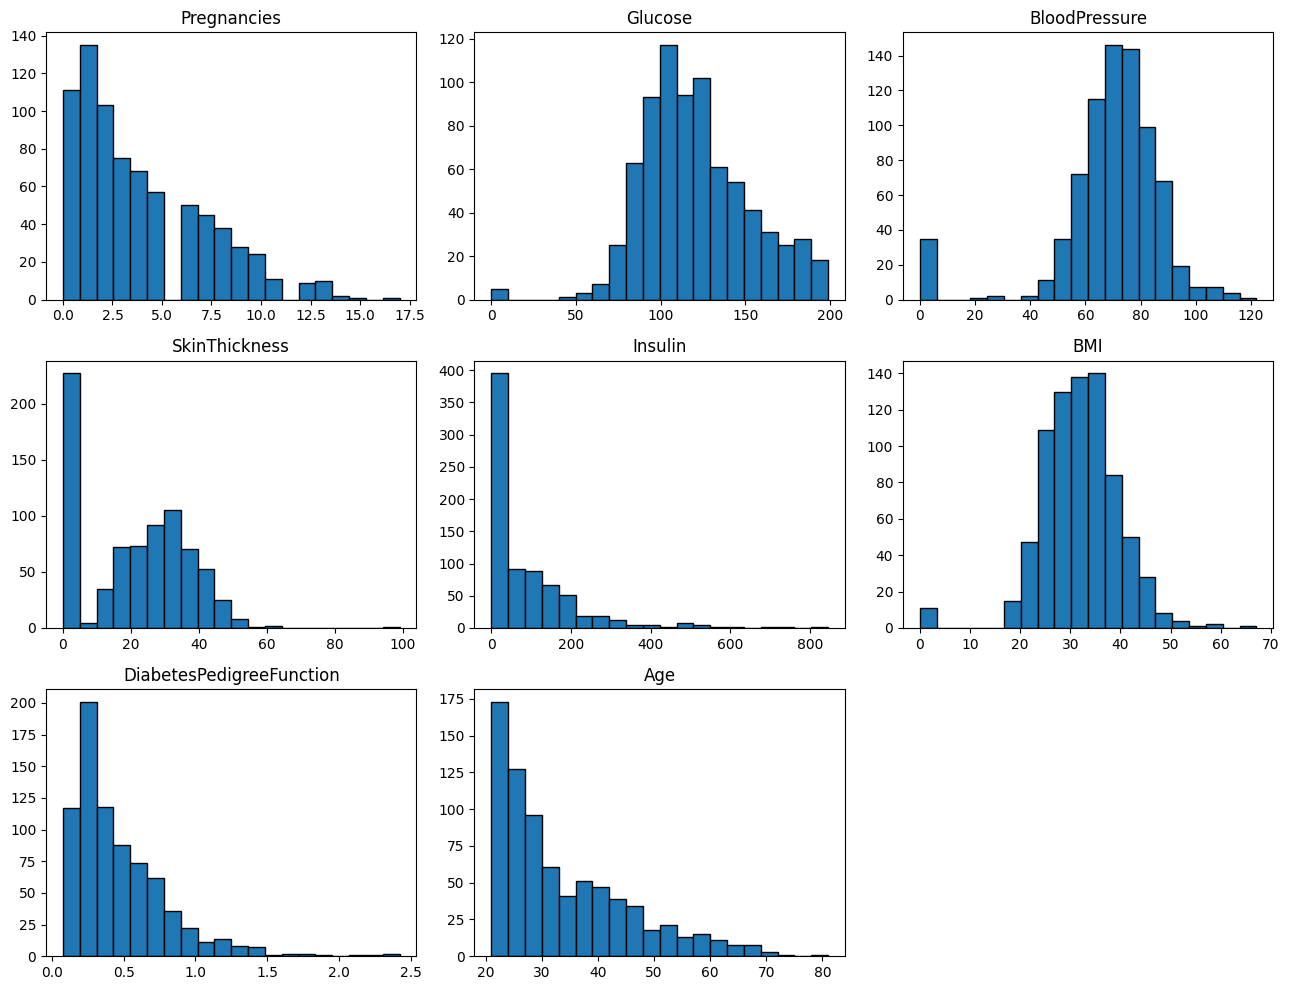

In [ ]:
#Histograms for each feature
featuresDF.hist(figsize=(13,10),bins=20, edgecolor='black', grid=False)
plt.grid(False)
plt.tight_layout()


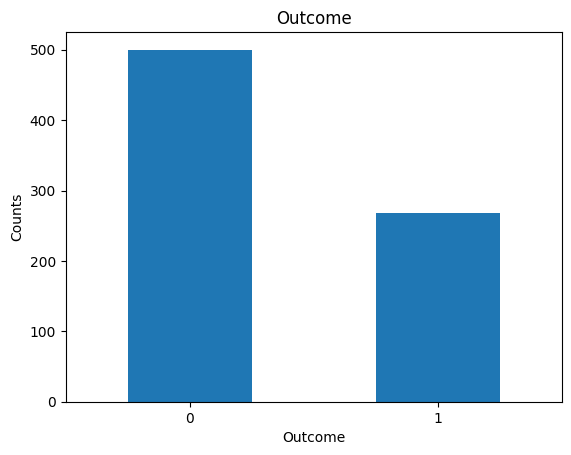

In [ ]:
#For the bar plot we have to count values, otherwise it would show bars for each record
df['Outcome'].value_counts().plot.bar(rot=0)
plt.xlabel('Outcome')
plt.ylabel('Counts')
plt.title('Outcome')
plt.show()

### ΕΡΩΤΗΜΑ 2

In [ ]:
#Convert features dataframe to numpy array
x = featuresDF.to_numpy()
x

array([[  6.   , 148.   ,  72.   , ...,  33.6  ,   0.627,  50.   ],
       [  1.   ,  85.   ,  66.   , ...,  26.6  ,   0.351,  31.   ],
       [  8.   , 183.   ,  64.   , ...,  23.3  ,   0.672,  32.   ],
       ...,
       [  5.   , 121.   ,  72.   , ...,  26.2  ,   0.245,  30.   ],
       [  1.   , 126.   ,  60.   , ...,  30.1  ,   0.349,  47.   ],
       [  1.   ,  93.   ,  70.   , ...,  30.4  ,   0.315,  23.   ]])

In [ ]:
#Convert Outcome dataframe column to numpy array
y = df['Outcome'].to_numpy()
y

array([1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0,
       1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,
       1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 0, 0, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1,

In [ ]:
#Split into training and test set
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.7, test_size=0.3, random_state=0)
print("Number of training examples, number of features: ", x_train.shape)
print("Number of training target examples: ", y_train.shape)
print("Number of test examples, number of features: ", x_test.shape)
print("Number of test target examples: ", y_test.shape)

Number of training examples, number of features:  (537, 8)
Number of training target examples:  (537,)
Number of test examples, number of features:  (231, 8)
Number of test target examples:  (231,)


### ΕΡΩΤΗΜΑ 3

In [ ]:
#Create the model
logistic_model = LogisticRegression(max_iter=5000,random_state=0)

In [ ]:
#Fit the model with training sets
logistic_model.fit(x_train,y_train)

LogisticRegression(max_iter=5000, random_state=0)

In [ ]:
#Running the model predictions against training and test sets
y_prediction_train = logistic_model.predict(x_train)
y_prediction_test = logistic_model.predict(x_test)

In [ ]:
#Calculation of accuracy scores
train_accuracy = accuracy_score(y_train, y_prediction_train)
test_accuracy = accuracy_score(y_test, y_prediction_test)

print("Train accuracy: ", train_accuracy)
print("Test accuracy: ", test_accuracy)

Train accuracy:  0.7653631284916201
Test accuracy:  0.7792207792207793


Παρατηρούμε ότι η ακρίβεια του test set είναι ελαφρώς υψηλότερη από αυτήν του training set, σε αντίθεση με το συνηθισμένο μοτίβο όπου είναι ελαφρώς χαμηλότερη. Θα περιμέναμε το μοντέλο να προβλέψει καλύτερα ως προς το training set, καθώς είναι δεδομένα πάνω στα οποία έχει εκπαιδευτεί.

### ΕΡΩΤΗΜΑ 4

In [ ]:
#Data normalization
scaler = StandardScaler()
scaler.fit(x_train)

scaled_x_train = scaler.transform(x_train)
scaled_x_test = scaler.transform(x_test)

In [ ]:
#Model Training - Evaluation
logistic_model.fit(scaled_x_train, y_train)

y_pred = logistic_model.predict(scaled_x_test)
accuracy = accuracy_score(y_test, y_pred)
accuracy_percentage = round(accuracy*100, 2)

print(f'The accuracy of the model is: {accuracy_percentage}')

The accuracy of the model is: 77.92


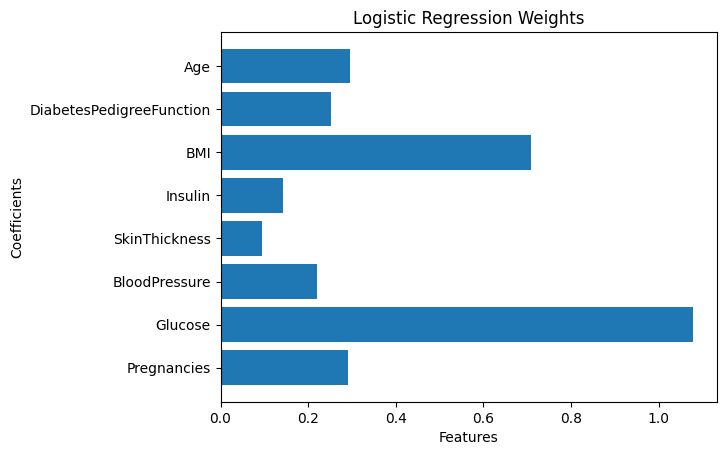

In [ ]:
coeffs = logistic_model.coef_[0]
importance_weights = np.abs(coeffs)
plt.barh(featuresDF.columns, importance_weights)
plt.title('Logistic Regression Weights')
plt.xlabel('Features')
plt.ylabel('Coefficients')
plt.show()

Τα δεδομένα επιβεβαιώνουν τις κλινικές μελέτες, καθώς παρατηρούμε ότι το βάρος του ταξινομητή για το feature της γλυκόζης είναι το υψηλότερο από όλα τα υπόλοιπα χαρακτηριστικά, οπότε είναι το σημαντικότερο για την τελική πρόβλεψη. Ακολουθεί ο Δείκτης Μάζας Σώματος ως το δεύτερο σημαντικότερο χαρακτηριστικό.

### ΕΡΩΤΗΜΑ 5

In [ ]:
#Find Age column index in Numpy Array
age_index = list(featuresDF.columns).index('Age')
age_index

7

In [ ]:
#Populate the three separate age groups
young_group = x_test[:,age_index] <= 25
mid_group = (x_test[:,age_index] > 25) & (x_test[:,age_index] <= 50)
old_group = x_test[:,age_index] > 50

In [ ]:
young_group_acc = accuracy_score(y_test[young_group], y_prediction_test[young_group])
young_group_acc

0.8555555555555555

In [ ]:
mid_group_acc = accuracy_score(y_test[mid_group], y_prediction_test[mid_group])
mid_group_acc

0.7

In [ ]:
old_group_acc = accuracy_score(y_test[old_group], y_prediction_test[old_group])
old_group_acc

0.9047619047619048

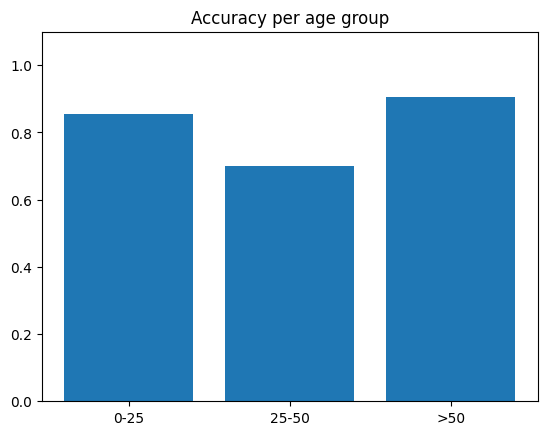

In [ ]:
labels = ['0-25','25-50','>50']
accs = [young_group_acc,mid_group_acc,old_group_acc]

plt.bar(labels,accs)
plt.ylim(0,1.1)
plt.title('Accuracy per age group')
plt.show()

Παρατηρούμε ότι ο ταξινομητής τα πάει πολύ καλά για τις ηλικίες 0-25 με ακρίβεια πάνω από 85%, εξαιρετική ακρίβεια (περίπου 90%) στις ηλικίες άνω των 50 και λίγο χειρότερη ακρίβεια (70%) για το ηλικιακό group 25-50.

### ΕΡΩΤΗΜΑ 6

Στην συγκεκριμένη εφαρμογή, είναι προτιμότερο ο ταξινομητής να προβλέψει ως ψευδώς θετικό ένα δείγμα (να προβλέψουμε οτι ο ασθενής έχει διαβήτη ενώ δεν έχει) παρά το αντίθετο, επειδη πρόκεται για μια εφαρμογή υγείας. Εαν ένα δείγμα προβλεφθεί εώς ψευδώς αρνητικό (δηλαδή ο ασθενής να έχει διαβήτη, αλλα ο ταξινομητής να προβλέψει οτι δεν έχει) θέτει σε κίνδυνο τον ασθενή διότι αγνοεί ενα θέμα υγείας το οποίο χρήζει άμεση ιατρική αντιμετώπιση.

## ΜΕΡΟΣ 2 - ΓΡΑΜΜΙΚΗ ΠΑΛΙΝΔΡΟΜΗΣΗ

### ΕΡΩΤΗΜΑ 1

In [ ]:
df = pd.read_csv('diabetes.csv')
df

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1


In [ ]:
#Create new dataframe that keeps only selected features, without Outcome
featuresDF = df[['Pregnancies','BloodPressure','BMI','Age']]
featuresDF

,Pregnancies,BloodPressure,BMI,Age
0,6,72,33.6,50
1,1,66,26.6,31
2,8,64,23.3,32
3,1,66,28.1,21
4,0,40,43.1,33
...,...,...,...,...
763,10,76,32.9,63
764,2,70,36.8,27
765,5,72,26.2,30
766,1,60,30.1,47


In [ ]:
x = featuresDF.to_numpy()
x

array([[ 6. , 72. , 33.6, 50. ],
       [ 1. , 66. , 26.6, 31. ],
       [ 8. , 64. , 23.3, 32. ],
       ...,
       [ 5. , 72. , 26.2, 30. ],
       [ 1. , 60. , 30.1, 47. ],
       [ 1. , 70. , 30.4, 23. ]])

In [ ]:
y = df['Glucose'].to_numpy()
y

array([148,  85, 183,  89, 137, 116,  78, 115, 197, 125, 110, 168, 139,
       189, 166, 100, 118, 107, 103, 115, 126,  99, 196, 119, 143, 125,
       147,  97, 145, 117, 109, 158,  88,  92, 122, 103, 138, 102,  90,
       111, 180, 133, 106, 171, 159, 180, 146,  71, 103, 105, 103, 101,
        88, 176, 150,  73, 187, 100, 146, 105,  84, 133,  44, 141, 114,
        99, 109, 109,  95, 146, 100, 139, 126, 129,  79,   0,  62,  95,
       131, 112, 113,  74,  83, 101, 137, 110, 106, 100, 136, 107,  80,
       123,  81, 134, 142, 144,  92,  71,  93, 122, 163, 151, 125,  81,
        85, 126,  96, 144,  83,  95, 171, 155,  89,  76, 160, 146, 124,
        78,  97,  99, 162, 111, 107, 132, 113,  88, 120, 118, 117, 105,
       173, 122, 170,  84,  96, 125, 100,  93, 129, 105, 128, 106, 108,
       108, 154, 102,  57, 106, 147,  90, 136, 114, 156, 153, 188, 152,
        99, 109,  88, 163, 151, 102, 114, 100, 131, 104, 148, 120, 110,
       111, 102, 134,  87,  79,  75, 179,  85, 129, 143, 130,  8

In [ ]:
#Split into training and test set
x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.7, test_size=0.3, random_state=0)
print("Number of training examples, number of features: ", x_train.shape)
print("Number of training target examples: ", y_train.shape)
print("Number of test examples, number of features: ", x_test.shape)
print("Number of test target examples: ", y_test.shape)

Number of training examples, number of features:  (537, 4)
Number of training target examples:  (537,)
Number of test examples, number of features:  (231, 4)
Number of test target examples:  (231,)


### ΕΡΩΤΗΜΑ 2

In [ ]:
#Create the linear model
linear_model = LinearRegression()

In [ ]:
#Fit the model with training sets
linear_model.fit(x_train,y_train)

LinearRegression()

In [ ]:
#Running the model predictions against training and test sets
y_prediction_test = linear_model.predict(x_test)

In [ ]:
#Calculation of accuracy scores
mse = mean_squared_error(y_test, y_prediction_test)
mae = mean_absolute_error(y_test, y_prediction_test)

print("MSE : ", mse)
print("MAE : ", mae)

MSE :  929.8883492746899
MAE :  23.599990462075155


Η καταλληλότερη μετρική είναι το Μέσο Απόλυτο Σφάλμα (Mean Absolute Error, MAE) καθώς είναι πιο ανθεκτική τόσο στα μικρά όσο και στα μεγάλα σφάλματα, σε αντίθεση με το Μέσο Τετραγωνικό Σφάλμα όπου δίνει έμφαση στα μεγάλα σφάλματα.

### ΕΡΩΤΗΜΑ 3

In [ ]:
#Data normalization
scaler = StandardScaler()
scaler.fit(x_train)

scaled_x_train = scaler.transform(x_train)
scaled_x_test = scaler.transform(x_test)

In [ ]:
#Model Training - Evaluation
linear_model.fit(scaled_x_train, y_train)
y_pred = linear_model.predict(scaled_x_test)

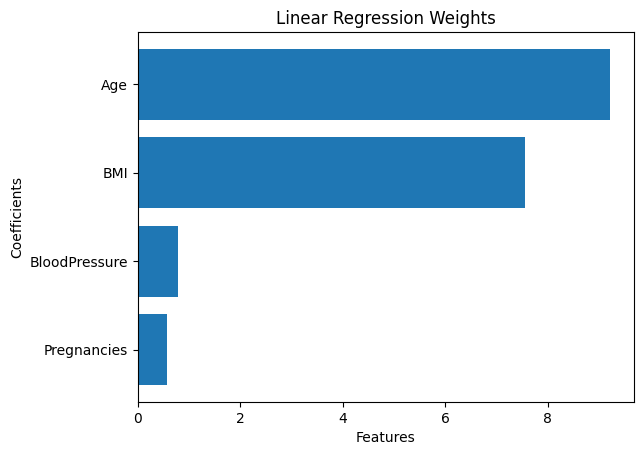

In [ ]:
coeffs = linear_model.coef_
importance_weights = np.abs(coeffs)
plt.barh(featuresDF.columns, importance_weights)
plt.title('Linear Regression Weights')
plt.xlabel('Features')
plt.ylabel('Coefficients')
plt.show()

Η ηλικία είναι η σημαντικότερη μεταβλητή για την πρόβλεψη της γλυκόζης, καθώς έχει τον μεγαλύτερο συντελεστή/βάρος από όλες τις μεταβλητές στο μοντέλο της Γραμμικής Παλινδρόμησης.